In [1]:
import pandas as pd
import statsmodels.api as sm

df = pd.read_excel("Real estate valuation data set.xlsx")

df.head()

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.916667,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.916667,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583333,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500000,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833333,5.0,390.56840,5,24.97937,121.54245,43.1


In [2]:
print(df.columns.tolist())
print(df.shape)

['No', 'X1 transaction date', 'X2 house age', 'X3 distance to the nearest MRT station', 'X4 number of convenience stores', 'X5 latitude', 'X6 longitude', 'Y house price of unit area']
(414, 8)


In [4]:
X_distance = df[["X3 distance to the nearest MRT station"]]

y = df["Y house price of unit area"]
model_simple = sm.OLS(
    y,
    sm.add_constant(X_distance)
)

result_simple = model_simple.fit()

print(result_simple.summary())

                                OLS Regression Results                                
Dep. Variable:     Y house price of unit area   R-squared:                       0.454
Model:                                    OLS   Adj. R-squared:                  0.452
Method:                         Least Squares   F-statistic:                     342.2
Date:                        Tue, 27 Oct 2026   Prob (F-statistic):           4.64e-56
Time:                                12:17:40   Log-Likelihood:                -1542.5
No. Observations:                         414   AIC:                             3089.
Df Residuals:                             412   BIC:                             3097.
Df Model:                                   1                                         
Covariance Type:                    nonrobust                                         
                                             coef    std err          t      P>|t|      [0.025      0.975]
-----------------------

In [5]:
X_multiple = df[[
    "X3 distance to the nearest MRT station",
    "X2 house age",
    "X4 number of convenience stores"
]]

model_multiple = sm.OLS(
    y,
    sm.add_constant(X_multiple)
)

result_multiple = model_multiple.fit()

print(result_multiple.summary())

                                OLS Regression Results                                
Dep. Variable:     Y house price of unit area   R-squared:                       0.541
Model:                                    OLS   Adj. R-squared:                  0.538
Method:                         Least Squares   F-statistic:                     161.1
Date:                        Tue, 27 Oct 2026   Prob (F-statistic):           5.44e-69
Time:                                12:20:22   Log-Likelihood:                -1506.5
No. Observations:                         414   AIC:                             3021.
Df Residuals:                             410   BIC:                             3037.
Df Model:                                   3                                         
Covariance Type:                    nonrobust                                         
                                             coef    std err          t      P>|t|      [0.025      0.975]
-----------------------

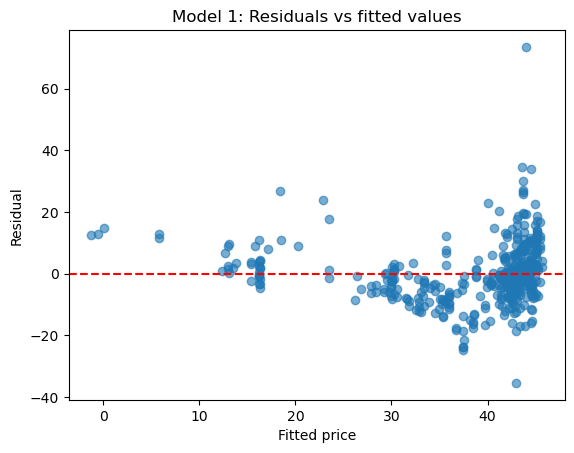

In [6]:
import matplotlib.pyplot as plt

plt.scatter(
    result_simple.fittedvalues,
    result_simple.resid,
    alpha=0.6
)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Fitted price")
plt.ylabel("Residual")
plt.title("Model 1: Residuals vs fitted values")

plt.show()

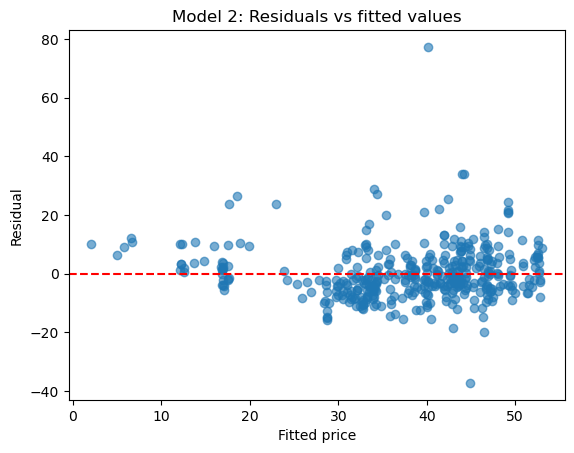

In [7]:
plt.scatter(
    result_multiple.fittedvalues,
    result_multiple.resid,
    alpha=0.6
)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Fitted price")
plt.ylabel("Residual")
plt.title("Model 2: Residuals vs fitted values")

plt.show()

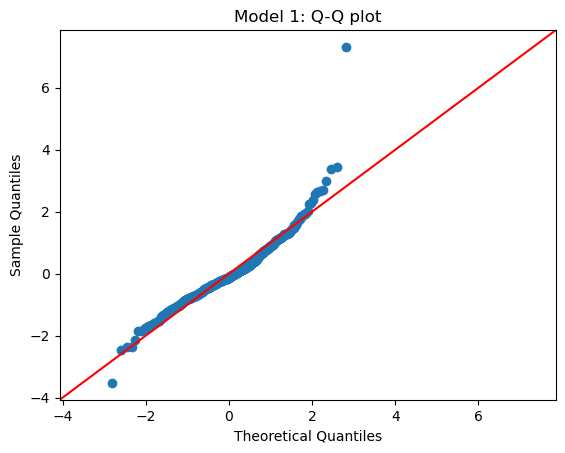

In [8]:
sm.qqplot(
    result_simple.resid,
    fit=True,
    line="45"
)

plt.title("Model 1: Q-Q plot")
plt.show()

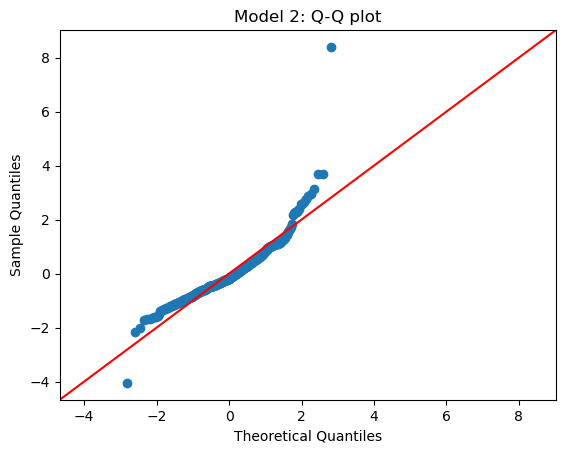

In [9]:
sm.qqplot(
    result_multiple.resid,
    fit=True,
    line="45"
)

plt.title("Model 2: Q-Q plot")
plt.show()

In [10]:
diagnostics = df.copy()

diagnostics["fitted_model1"] = result_simple.fittedvalues
diagnostics["residual_model1"] = result_simple.resid

diagnostics["fitted_model2"] = result_multiple.fittedvalues
diagnostics["residual_model2"] = result_multiple.resid

largest_errors = (
    diagnostics["residual_model2"]
    .abs()
    .nlargest(5)
    .index
)

diagnostics.loc[
    largest_errors,
    [
        "No",
        "Y house price of unit area",
        "X3 distance to the nearest MRT station",
        "X2 house age",
        "X4 number of convenience stores",
        "fitted_model2",
        "residual_model2"
    ]
]

,No,Y house price of unit area,X3 distance to the nearest MRT station,X2 house age,X4 number of convenience stores,fitted_model2,residual_model2
270,271,117.5,252.5822,10.8,1,40.185213,77.314787
113,114,7.6,393.2606,14.8,6,44.904275,-37.304275
220,221,78.3,186.5101,37.2,9,44.244770,34.055230
312,313,78.0,318.5292,35.4,9,43.989762,34.010238
126,127,62.9,804.6897,38.6,4,34.078291,28.821709


In [12]:
import numpy as np

distance = df["X3 distance to the nearest MRT station"]

print("whether all distance is bigger than 0：", (distance > 0).all())

whether all distance is bigger than 0： True


In [13]:
df_log_distance = df.copy()

df_log_distance["log_distance"] = np.log(distance)

In [14]:
X_log_distance = df_log_distance[[
    "log_distance",
    "X2 house age",
    "X4 number of convenience stores"
]]

model_log_distance = sm.OLS(
    y,
    sm.add_constant(X_log_distance)
)

result_log_distance = model_log_distance.fit()

print(result_log_distance.summary())

                                OLS Regression Results                                
Dep. Variable:     Y house price of unit area   R-squared:                       0.579
Model:                                    OLS   Adj. R-squared:                  0.576
Method:                         Least Squares   F-statistic:                     187.6
Date:                        Tue, 27 Oct 2026   Prob (F-statistic):           1.43e-76
Time:                                12:31:16   Log-Likelihood:                -1488.8
No. Observations:                         414   AIC:                             2986.
Df Residuals:                             410   BIC:                             3002.
Df Model:                                   3                                         
Covariance Type:                    nonrobust                                         
                                      coef    std err          t      P>|t|      [0.025      0.975]
------------------------------

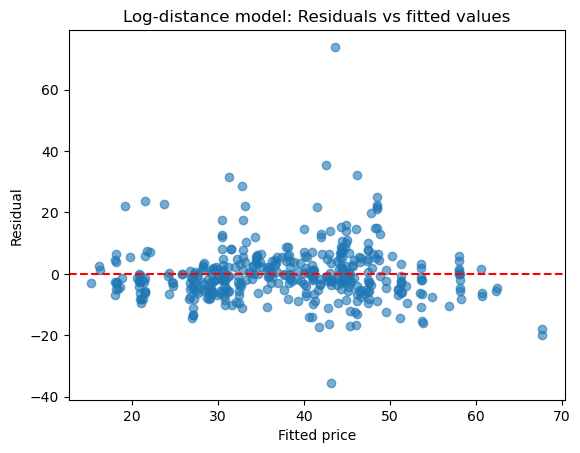

In [15]:
plt.scatter(
    result_log_distance.fittedvalues,
    result_log_distance.resid,
    alpha=0.6
)

plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Fitted price")
plt.ylabel("Residual")
plt.title("Log-distance model: Residuals vs fitted values")
plt.show()

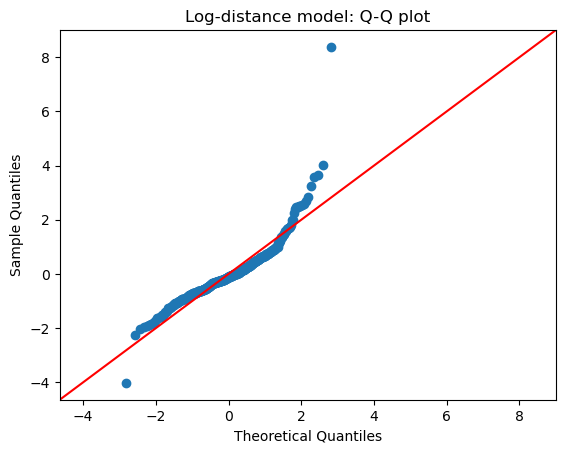

In [16]:
sm.qqplot(
    result_log_distance.resid,
    fit=True,
    line="45"
)

plt.title("Log-distance model: Q-Q plot")
plt.show()

In [17]:
print("whether all price bigger than 0：", (y > 0).all())

whether all price bigger than 0： True


In [18]:
log_price = np.log(y)

In [19]:
model_log_price = sm.OLS(
    log_price,
    sm.add_constant(X_multiple)
)

result_log_price = model_log_price.fit()

print(result_log_price.summary())

                                OLS Regression Results                                
Dep. Variable:     Y house price of unit area   R-squared:                       0.634
Model:                                    OLS   Adj. R-squared:                  0.631
Method:                         Least Squares   F-statistic:                     236.4
Date:                        Tue, 27 Oct 2026   Prob (F-statistic):           5.05e-89
Time:                                12:34:49   Log-Likelihood:                 8.1469
No. Observations:                         414   AIC:                            -8.294
Df Residuals:                             410   BIC:                             7.810
Df Model:                                   3                                         
Covariance Type:                    nonrobust                                         
                                             coef    std err          t      P>|t|      [0.025      0.975]
-----------------------

In [20]:
print(X_multiple.columns)

Index(['X3 distance to the nearest MRT station', 'X2 house age',
       'X4 number of convenience stores'],
      dtype='object')


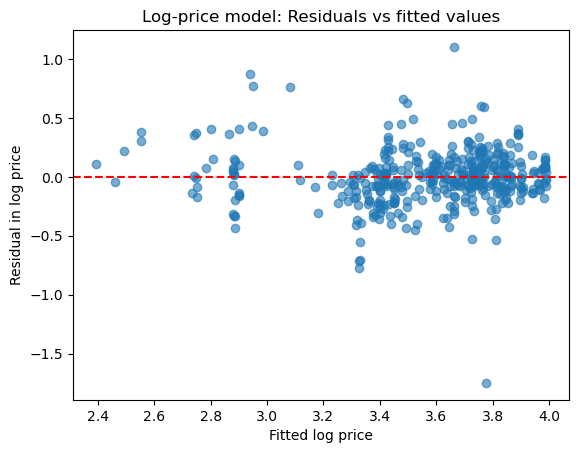

In [21]:
plt.scatter(
    result_log_price.fittedvalues,
    result_log_price.resid,
    alpha=0.6
)

plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Fitted log price")
plt.ylabel("Residual in log price")
plt.title("Log-price model: Residuals vs fitted values")

plt.show()

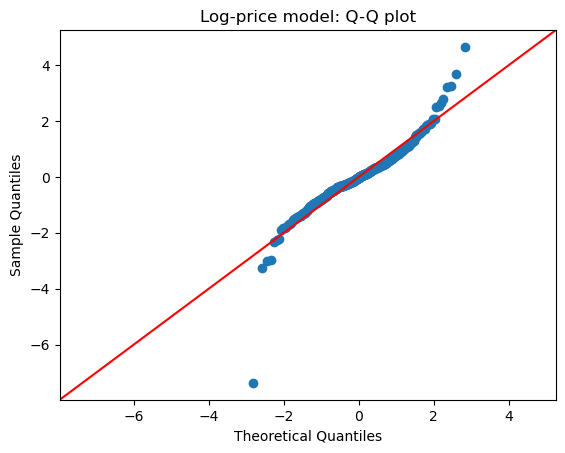

In [22]:
sm.qqplot(
    result_log_price.resid,
    fit=True,
    line="45"
)

plt.title("Log-price model: Q-Q plot")
plt.show()

In [23]:
model_log_price_simple = sm.OLS(
    log_price,
    sm.add_constant(X_distance)
)

result_log_price_simple = model_log_price_simple.fit()

print(result_log_price_simple.summary())

                                OLS Regression Results                                
Dep. Variable:     Y house price of unit area   R-squared:                       0.566
Model:                                    OLS   Adj. R-squared:                  0.565
Method:                         Least Squares   F-statistic:                     537.3
Date:                        Tue, 27 Oct 2026   Prob (F-statistic):           1.09e-76
Time:                                12:37:51   Log-Likelihood:                -26.939
No. Observations:                         414   AIC:                             57.88
Df Residuals:                             412   BIC:                             65.93
Df Model:                                   1                                         
Covariance Type:                    nonrobust                                         
                                             coef    std err          t      P>|t|      [0.025      0.975]
-----------------------

In [24]:
distance_name = "X3 distance to the nearest MRT station"

comparison = pd.DataFrame({
    "Model": [
        "Log-price: distance only",
        "Log-price: distance + age + shops"
    ],
    "N": [
        result_log_price_simple.nobs,
        result_log_price.nobs
    ],
    "Distance coefficient": [
        result_log_price_simple.params[distance_name],
        result_log_price.params[distance_name]
    ],
    "Adjusted R-squared": [
        result_log_price_simple.rsquared_adj,
        result_log_price.rsquared_adj
    ]
})

comparison

,Model,N,Distance coefficient,Adjusted R-squared
0,Log-price: distance only,414.0,-0.000234,0.564958
1,Log-price: distance + age + shops,414.0,-0.000186,0.630995


In [25]:
log_diagnostics = df.copy()

log_diagnostics["log_price_residual"] = result_log_price.resid

largest_log_errors = (
    log_diagnostics["log_price_residual"]
    .abs()
    .nlargest(5)
    .index
)

log_diagnostics.loc[
    largest_log_errors,
    [
        "No",
        "Y house price of unit area",
        "X3 distance to the nearest MRT station",
        "X2 house age",
        "X4 number of convenience stores",
        "log_price_residual"
    ]
]

,No,Y house price of unit area,X3 distance to the nearest MRT station,X2 house age,X4 number of convenience stores,log_price_residual
113,114,7.6,393.2606,14.8,6,-1.748596
270,271,117.5,252.5822,10.8,1,1.102729
148,149,45.1,3780.5900,16.4,0,0.870626
330,331,12.8,1156.7770,32.0,0,-0.777035
344,345,41.2,3085.1700,34.6,0,0.767507


In [26]:
keep = df["No"] != 271

result_log_price_without271 = sm.OLS(
    log_price.loc[keep],
    sm.add_constant(X_multiple.loc[keep])
).fit()

In [27]:
sensitivity = pd.DataFrame({
    "Model": [
        "All observations",
        "Excluding No. 271"
    ],
    "N": [
        result_log_price.nobs,
        result_log_price_without271.nobs
    ],
    "Distance coefficient": [
        result_log_price.params[distance_name],
        result_log_price_without271.params[distance_name]
    ],
    "CI lower": [
        result_log_price.conf_int().loc[distance_name, 0],
        result_log_price_without271.conf_int().loc[distance_name, 0]
    ],
    "CI upper": [
        result_log_price.conf_int().loc[distance_name, 1],
        result_log_price_without271.conf_int().loc[distance_name, 1]
    ]
})

sensitivity

,Model,N,Distance coefficient,CI lower,CI upper
0,All observations,414.0,-0.000186,-0.000209,-0.000163
1,Excluding No. 271,413.0,-0.000182,-0.000204,-0.000159


In [28]:
result_log_price_hc3 = model_log_price.fit(
    cov_type="HC3",
    use_t=True
)

print(result_log_price_hc3.summary())

                                OLS Regression Results                                
Dep. Variable:     Y house price of unit area   R-squared:                       0.634
Model:                                    OLS   Adj. R-squared:                  0.631
Method:                         Least Squares   F-statistic:                     200.6
Date:                        Tue, 27 Oct 2026   Prob (F-statistic):           4.58e-80
Time:                                12:46:38   Log-Likelihood:                 8.1469
No. Observations:                         414   AIC:                            -8.294
Df Residuals:                             410   BIC:                             7.810
Df Model:                                   3                                         
Covariance Type:                          HC3                                         
                                             coef    std err          t      P>|t|      [0.025      0.975]
-----------------------

In [29]:
inference_comparison = pd.DataFrame({
    "Standard errors": ["Conventional", "HC3"],
    
    "Distance coefficient": [
        result_log_price.params[distance_name],
        result_log_price_hc3.params[distance_name]
    ],
    
    "Standard error": [
        result_log_price.bse[distance_name],
        result_log_price_hc3.bse[distance_name]
    ],
    
    "p-value": [
        result_log_price.pvalues[distance_name],
        result_log_price_hc3.pvalues[distance_name]
    ],
    
    "CI lower": [
        result_log_price.conf_int().loc[distance_name, 0],
        result_log_price_hc3.conf_int().loc[distance_name, 0]
    ],
    
    "CI upper": [
        result_log_price.conf_int().loc[distance_name, 1],
        result_log_price_hc3.conf_int().loc[distance_name, 1]
    ]
})

inference_comparison

,Standard errors,Distance coefficient,Standard error,p-value,CI lower,CI upper
0,Conventional,-0.000186,0.000012,7.346844e-45,-0.000209,-0.000163
1,HC3,-0.000186,0.000013,1.679033e-38,-0.000211,-0.000161


In [30]:
location_counts = (
    df.groupby(["X5 latitude", "X6 longitude"])
    .size()
    .sort_values(ascending=False)
)

print("Total number of transactions:", len(df))
print("Number of unique coordinate groups:", len(location_counts))
print("Number of coordinate groups with multiple transactions:", (location_counts > 1).sum())
print("Maximum number of transactions at the same coordinates:", location_counts.max())

location_counts.head(10)

Total number of transactions: 414
Number of unique coordinate groups: 259
Number of coordinate groups with multiple transactions: 68
Maximum number of transactions at the same coordinates: 13


X5 latitude  X6 longitude
24.98203     121.54348       13
24.97433     121.54310       11
24.96515     121.53737        9
24.96674     121.54067        8
24.95204     121.54842        8
24.94155     121.50381        7
24.97937     121.54245        6
24.94297     121.50342        6
24.96299     121.51284        6
24.97110     121.53170        5
dtype: int64